# Poland — Actuarial Climate Index (five land components)

**Offline calculation and coverage assessment.** All inputs come from this project's existing files. There is no download, remote map layer, credential prompt, or data acquisition step. Water/sea level is excluded everywhere, including Pomorskie.

**Requested period:** 1 January 1961–30 April 2026. **Reference period:** 1961–1991 inclusive, matching the voivodeship notebooks (31 years). **Grid:** every unique rectangle in `data/poland/poland_era5land_grid.csv`.

\[
ACI_{land5}=(T90p-T10p+Rx5day+CDD+W90p)/5.
\]

This follows `dolnoslaskie_aci_workflow.ipynb`, `mazowieckie_aci_workflow.ipynb`, and the land component of `pomorskie_independent_aci_workflow.ipynb`:

- The **national series** first averages daily weather over all unique Polish grid points with equal point weights, then calculates national thresholds and standardized components. Voivodeship indices are not averaged to manufacture a national series. This convention matches the previous notebooks; it is not an area-weighted index.
- The **map** calculates thresholds and components independently for each cell. Seasonal values require all three monthly components; December belongs to the following winter. Annual values require all twelve months. Decade views average only complete constituent seasons/years and report their count.
- Temperature thresholds retain the local `iaci` library's five-day type-8 quantiles and its calendar/leap-day convention. Temperature standardization divides by the mean of the daytime and nighttime reference standard deviations. Wind uses the reference calendar-day mean plus the normal 90% quantile times its sample standard deviation. CDD is the longest within-month run of precipitation below 1 mm divided by calendar days in that month. Rx5day retains the existing library's missing-rain-as-zero rolling sum followed by its monthly missing-day mask.
- This reproduces the project's implementation; the methodological qualifications already recorded in the regional notebooks still apply. It is a five-component adaptation, not the six-component coastal index.

**Coverage matters:** the audit below determines feasibility from the actual values, rather than file counts. A national result is left missing unless all Polish cells have daily weather and a complete national reference period. Cell results require the complete 1961–1991 daily baseline; later months permit at most three missing days per variable, as in `iaci`. Missing data and zero reference variance remain missing, never zero. A mean over available cell indices is exported only as a clearly labelled coverage diagnostic.

Run all cells using the project's Python environment. Results are saved under `output/poland/national/`. The notebook contains the complete calculation code and a static map; the linked interactive map works offline and shows values for every rectangle with data, and the reason when a value is missing.


In [1]:
from pathlib import Path
import base64, gzip, hashlib, json, sys, warnings
from statistics import NormalDist
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Image, IFrame

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "python_iaci/iaci").is_dir():
    raise RuntimeError("Run the notebook with the project root as its working directory.")
sys.path.insert(0, str(PROJECT_ROOT / "python_iaci"))
from iaci import (climate_input, t90p_std, t10p_std, rx5day_std,
                  w90p_std, calculate_standardized, merge_components)
START, END = pd.Timestamp("1961-01-01"), pd.Timestamp("2026-04-30")
BASE_RANGE, TEMP_WINDOW_DAYS = (1961, 1991), 5
VARIABLES = ["TMAX", "TMIN", "PRCP", "WP"]
METRICS = ["T90p", "T10p_oriented", "Rx5day", "CDD", "W90p", "ACI_land5"]
DATES = pd.date_range(START, END, freq="D")
MONTHS = pd.period_range(START, END, freq="M")
BASE_DAYS = (DATES.year >= BASE_RANGE[0]) & (DATES.year <= BASE_RANGE[1])
OUTPUT_DIR = PROJECT_ROOT / "output/poland/national"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
REGIONS = sorted(p.parent.name for p in (PROJECT_ROOT / "data/poland/grid").glob("*/grid.csv"))
assert len(REGIONS) == 16, "Expected all sixteen regional grid lists."
print(f"Local inputs only | {START.date()} to {END.date()} | reference {BASE_RANGE}")


Local inputs only | 1961-01-01 to 2026-04-30 | reference (1961, 1991)


## 1. Assemble the Polish grid and identify local sources

The national grid is checked against the union of all sixteen regional lists. Coordinates are matched by their 0.1° centres, not by file order or nearest-neighbour interpolation. Duplicate coordinates are rejected. The saved NUTS2 boundary is used only for drawing: it does not remove or create grid cells.

Sources are tried in this order: regional daily NetCDF, a complete local hourly year when the daily year is absent, existing daily point CSVs for remaining gaps, and the earlier Pomeranian processed rectangle for matching points. No `.partial` archive is accepted. The rectangle source is compared with overlapping regional observations before any fallback values are used. Original input files are never changed. Every source used appears in the source audit with the number of values it supplied.


In [2]:
def coord_keys(frame):
    return list(zip(np.rint(frame.latitude.to_numpy() * 10).astype(int),
                    np.rint(frame.longitude.to_numpy() * 10).astype(int)))

regional_grids = {}
for region in REGIONS:
    g = pd.read_csv(PROJECT_ROOT / "data/poland/grid" / region / "grid.csv")
    assert not g[["latitude", "longitude"]].isna().any().any()
    assert not g[["latitude", "longitude"]].duplicated().any()
    g["region"] = region
    regional_grids[region] = g
union_grid = pd.concat(regional_grids.values(), ignore_index=True)
grid = pd.read_csv(PROJECT_ROOT / "data/poland/poland_era5land_grid.csv")
assert not grid[["latitude", "longitude"]].duplicated().any()
assert not union_grid[["latitude", "longitude"]].duplicated().any()
assert set(coord_keys(grid)) == set(coord_keys(union_grid)), "National and regional grids disagree."
grid = grid.merge(union_grid[["latitude", "longitude", "region"]],
                  on=["latitude", "longitude"], validate="one_to_one")
grid = grid.sort_values(["latitude", "longitude"]).reset_index(drop=True)
POINT_LOOKUP = {key: i for i, key in enumerate(coord_keys(grid))}
for region, g in regional_grids.items():
    g["national_point"] = [POINT_LOOKUP[k] for k in coord_keys(g)]
N = len(grid)
print(f"{N:,} unique Polish rectangles; {len(REGIONS)} voivodeships.")
display(grid.groupby(["region", "voivodeship"]).size().rename("rectangles").reset_index())


4,092 unique Polish rectangles; 16 voivodeships.


,region,voivodeship,rectangles
0,dolnoslaskie,Dolnośląskie,259
1,kujawsko_pomorskie,Kujawsko-pomorskie,236
2,lodzkie,Łódzkie,238
3,lubelskie,Lubelskie,327
4,lubuskie,Lubuskie,177
5,malopolskie,Małopolskie,193
6,mazowieckie,Mazowieckie,465
7,opolskie,Opolskie,116
8,podkarpackie,Podkarpackie,221
9,podlaskie,Podlaskie,272


In [3]:
source_rows, issue_rows = [], []

def extract_daily(ds, wanted):
    """Return exact coordinate pairs in wanted order; no interpolation."""
    if "point" in ds.dims:
        source_keys = list(zip(np.rint(ds.latitude.values * 10).astype(int),
                               np.rint(ds.longitude.values * 10).astype(int)))
        if len(source_keys) != len(set(source_keys)):
            raise ValueError("Duplicate coordinates in a point archive")
        lookup = {key: i for i, key in enumerate(source_keys)}
        pairs = [(j, lookup[k]) for j, k in enumerate(coord_keys(wanted)) if k in lookup]
        if not pairs:
            return np.array([], dtype=int), None
        js, ids = map(np.array, zip(*pairs))
        subset = ds[VARIABLES].isel(point=ids)
        block = np.stack([subset[v].transpose("time", "point").values for v in VARIABLES], axis=-1)
    else:
        lat = {round(float(x), 1): float(x) for x in ds.latitude.values}
        lon = {round(float(x), 1): float(x) for x in ds.longitude.values}
        js = np.array([j for j, row in enumerate(wanted.itertuples())
                       if round(row.latitude, 1) in lat and round(row.longitude, 1) in lon], dtype=int)
        if not len(js):
            return js, None
        chosen = wanted.iloc[js]
        subset = ds[VARIABLES].sel(
            latitude=xr.DataArray([lat[round(v, 1)] for v in chosen.latitude], dims="point"),
            longitude=xr.DataArray([lon[round(v, 1)] for v in chosen.longitude], dims="point"))
        block = np.stack([subset[v].transpose("time", "point").values for v in VARIABLES], axis=-1)
    return js, np.asarray(block, dtype=np.float32)

def hourly_to_daily(ds):
    """Same UTC conversions as the regional notebooks; require 24 observations."""
    t = ds.t2m - 273.15
    rain = (ds.tp * 1000).assign_coords(time=ds.time - np.timedelta64(1, "h"))
    speed = np.sqrt(ds.u10 ** 2 + ds.v10 ** 2)
    tc = t.resample(time="1D").count()
    wc = speed.resample(time="1D").count()
    return xr.Dataset({
        "TMAX": t.resample(time="1D").max().where(tc == 24),
        "TMIN": t.resample(time="1D").min().where(tc == 24),
        "PRCP": rain.resample(time="1D").sum(skipna=False).where(rain.resample(time="1D").count() == 24),
        "WP": (0.5 * 1.23 * speed.resample(time="1D").mean() ** 3).where(wc == 24),
    })

def insert_source(values, ds, wanted, path, region, kind, check_overlap=False):
    if not set(VARIABLES).issubset(ds.data_vars):
        raise ValueError(f"Missing variables in {path}")
    times = pd.DatetimeIndex(ds.time.values)
    if times.has_duplicates or not times.is_monotonic_increasing or not times.equals(times.normalize()):
        raise ValueError(f"Invalid daily calendar in {path}")
    inside = (times >= START) & (times <= END)
    if not inside.any():
        return
    ds = ds.isel(time=np.flatnonzero(inside))
    times = times[inside]
    js, block = extract_daily(ds, wanted)
    if block is None:
        return
    ti = DATES.get_indexer(times)
    current = values[ti[:, None], js[None, :], :]
    finite = np.isfinite(block)
    overlap = np.isfinite(current) & finite
    overlap_count = int(overlap.sum())
    if check_overlap and overlap_count:
        if not np.allclose(current[overlap], block[overlap], rtol=2e-5, atol=1e-4):
            raise ValueError(f"Fallback archive disagrees with existing daily data: {path}")
    fill = ~np.isfinite(current) & finite
    values[ti[:, None], js[None, :], :] = np.where(fill, block, current)
    source_rows.append({"region": region, "kind": kind, "path": str(path.relative_to(PROJECT_ROOT)),
                        "first_date": str(times.min().date()), "last_date": str(times.max().date()),
                        "matching_points": len(js), "filled_variable_values": int(fill.sum()),
                        "overlap_variable_values_checked": overlap_count if check_overlap else 0})

def load_region(region):
    wanted = regional_grids[region]
    values = np.full((len(DATES), len(wanted), 4), np.nan, dtype=np.float32)
    folder = PROJECT_ROOT / "data/poland" / ("pomorskie_independent" if region == "pomorskie" else region)
    for year in range(START.year, END.year + 1):
        daily = folder / "daily_grid" / f"{year}_daily.nc"
        hourly = folder / "arco_hourly" / f"{year}_arco.nc"
        if daily.exists():
            with xr.open_dataset(daily) as ds:
                insert_source(values, ds, wanted, daily, region, "regional_daily")
        elif hourly.exists():
            with xr.open_dataset(hourly) as ds:
                times = pd.DatetimeIndex(ds.time.values)
                first = pd.Timestamp(year, 1, 1)
                last = min(pd.Timestamp(year, 12, 31), END)
                expected = pd.date_range(first, last + pd.Timedelta(days=1), freq="h")
                if not times.equals(expected):
                    issue_rows.append({"region": region, "path": str(hourly.relative_to(PROJECT_ROOT)),
                                       "issue": "Hourly calendar incomplete; file not used"})
                    continue
                daily_ds = hourly_to_daily(ds).sel(time=slice(first, last))
                insert_source(values, daily_ds, wanted, hourly, region, "local_hourly_derived")
    # CSVs can supply gaps even when a regional daily block exists but is incomplete.
    for j, row in enumerate(wanted.itertuples()):
        if np.isfinite(values[:, j]).all():
            continue
        csv = folder / "grid_csv" / f"{row.latitude:.1f}_{row.longitude:.1f}.csv"
        if not csv.exists():
            continue
        frame = pd.read_csv(csv, parse_dates=["time"])
        if frame.time.duplicated().any():
            raise ValueError(f"Duplicate dates in {csv}")
        if not np.allclose(frame.latitude, row.latitude) or not np.allclose(frame.longitude, row.longitude):
            raise ValueError(f"CSV coordinate mismatch: {csv}")
        ti = DATES.get_indexer(frame.time)
        keep = ti >= 0
        current = values[ti[keep], j, :]
        block = frame.loc[keep, VARIABLES].to_numpy(dtype=np.float32)
        fill = ~np.isfinite(current) & np.isfinite(block)
        values[ti[keep], j, :] = np.where(fill, block, current)
        source_rows.append({"region": region, "kind": "point_csv", "path": str(csv.relative_to(PROJECT_ROOT)),
                            "filled_variable_values": int(fill.sum()), "matching_points": 1})
    fallback = PROJECT_ROOT / "data/pomerania/processed/processed_data.nc"
    if fallback.exists() and not np.isfinite(values).all():
        with xr.open_dataset(fallback) as ds:
            insert_source(values, ds, wanted, fallback, region, "legacy_rectangle", check_overlap=True)
    return values


## 2. Monthly component calculations

The batch implementation below avoids running the same calendar operations thousands of times. It preserves the local library's formulas; section 4 checks it against the original functions on a daily series from every region with a complete baseline, and against existing cell-result CSVs where available. The checks cover all months and all five components, including the oriented cold component.


In [4]:
MONTH_GROUPS = [np.flatnonzero(DATES.to_period("M") == month) for month in MONTHS]
BASE_MONTHS = (MONTHS.year >= BASE_RANGE[0]) & (MONTHS.year <= BASE_RANGE[1])
MONTH_DAY = DATES.strftime("%m-%d").to_numpy()
CALENDAR = pd.date_range("2000-01-01", "2000-12-31").strftime("%m-%d").to_numpy()
CALENDAR_ID = pd.Index(CALENDAR).get_indexer(MONTH_DAY)


def safe_mean(a, axis=0):
    count = np.isfinite(a).sum(axis=axis)
    return np.divide(np.nansum(a, axis=axis), count,
                     out=np.full(np.shape(count), np.nan), where=count > 0)

def safe_sd(a, axis=0):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        return np.nanstd(a, axis=axis, ddof=1)

def standardize_raw(raw):
    result = np.full_like(raw, np.nan, dtype=float)
    for month in range(1, 13):
        rows = MONTHS.month == month
        reference = raw[rows & BASE_MONTHS]
        mean, sd = safe_mean(reference), safe_sd(reference)
        result[rows] = np.divide(raw[rows] - mean, sd,
                                out=np.full_like(raw[rows], np.nan), where=sd > 0)
    return result

def temperature_thresholds(series):
    # Match iaci.thresholds.temperature_quantiles, including its leap-year convention.
    base_dates = DATES[BASE_DAYS]
    day_number = base_dates.dayofyear.to_numpy(dtype=float)
    day_number[(base_dates.month == 2) & (base_dates.day == 29)] = 59.5
    calendar_days = list(range(1, 366))
    calendar_days.insert(59, 59.5)
    day_vector = np.asarray(calendar_days)
    reference = np.asarray(series[BASE_DAYS], dtype=float)
    by_day = [reference[day_number == day] for day in day_vector]
    thresholds = np.full((366, series.shape[1], 2), np.nan)
    for i in range(366):
        sample = np.concatenate(by_day[max(0, i-2):min(366, i+3)], axis=0)
        count = np.isfinite(sample).sum(axis=0)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            q = np.quantile(sample, [0.10, 0.90], axis=0, method="median_unbiased").T
        q[count / TEMP_WINDOW_DAYS < 0.1] = np.nan
        thresholds[i] = q
    return thresholds

def monthly_percent(series, threshold, upper):
    output = np.full((len(MONTHS), series.shape[1]), np.nan)
    for m, ids in enumerate(MONTH_GROUPS):
        daily, limit = series[ids], threshold[CALENDAR_ID[ids]]
        valid = np.isfinite(daily) & np.isfinite(limit)
        flags = ((daily > limit) if upper else (daily < limit)) & valid
        denominator = valid.sum(axis=0)
        output[m] = np.divide(flags.sum(axis=0) * 100.0, denominator,
                              out=np.full(series.shape[1], np.nan), where=denominator > 0)
        output[m, (~np.isfinite(daily)).sum(axis=0) > 3] = np.nan
    return output

def temperature_standardized(day, night):
    combined = (day + night) / 2
    result = np.full_like(combined, np.nan)
    for month in range(1, 13):
        rows = MONTHS.month == month
        reference = rows & BASE_MONTHS
        mean = safe_mean(combined[reference])
        sd = (safe_sd(day[reference]) + safe_sd(night[reference])) / 2
        result[rows] = np.divide(combined[rows] - mean, sd,
                                out=np.full_like(combined[rows], np.nan), where=sd > 0)
    return result

def monthly_components(values):
    p = values.shape[1]
    result = np.full((len(MONTHS), p, len(METRICS)), np.nan)
    eligible = np.isfinite(values[BASE_DAYS]).all(axis=(0, 2))
    if not eligible.any():
        return result
    a = np.asarray(values[:, eligible], dtype=float)
    tx, tn, rain, wind = [a[:, :, j] for j in range(4)]
    txq, tnq = temperature_thresholds(tx), temperature_thresholds(tn)
    hot = temperature_standardized(monthly_percent(tx, txq[:, :, 1], True),
                                   monthly_percent(tn, tnq[:, :, 1], True))
    cold = temperature_standardized(monthly_percent(tx, txq[:, :, 0], False),
                                    monthly_percent(tn, tnq[:, :, 0], False))
    wind_threshold = np.full((366, a.shape[1]), np.nan)
    for i in range(366):
        sample = wind[BASE_DAYS & (CALENDAR_ID == i)]
        wind_threshold[i] = safe_mean(sample) + NormalDist().inv_cdf(0.90) * safe_sd(sample)
    wind_raw = monthly_percent(wind, wind_threshold, True)
    # Pandas rolling summation matches iaci.rx5day: missing precipitation enters as zero.
    rolling = pd.DataFrame(np.nan_to_num(rain, nan=0.0)).rolling(5, min_periods=5).sum().to_numpy()
    rx_raw = np.full((len(MONTHS), a.shape[1]), np.nan)
    cdd_raw = np.full_like(rx_raw, np.nan)
    for m, ids in enumerate(MONTH_GROUPS):
        rx_raw[m] = np.nanmax(rolling[ids], axis=0)
        run = np.zeros(a.shape[1], dtype=int)
        longest = run.copy()
        for day in rain[ids]:
            run = np.where(np.isfinite(day) & (day < 1.0), run + 1, 0)
            longest = np.maximum(longest, run)
        cdd_raw[m] = longest / len(ids)
        invalid = (~np.isfinite(rain[ids])).sum(axis=0) > 3
        rx_raw[m, invalid] = cdd_raw[m, invalid] = np.nan
    components = np.stack([hot, -cold, standardize_raw(rx_raw),
                           standardize_raw(cdd_raw), standardize_raw(wind_raw)], axis=-1)
    result[:, eligible, :5] = components
    result[:, eligible, 5] = components.sum(axis=-1) / 5
    assert not np.isinf(result).any()
    return result


## 3. Audit all daily inputs and calculate every eligible cell

Processing one voivodeship at a time keeps memory bounded. The national daily sums and counts always use the deduplicated national grid. A point remains in the coverage denominator even if it has no observations. The source audit, cell availability, and per-voivodeship summary are saved for inspection.


In [5]:
monthly_values = np.full((len(MONTHS), N, len(METRICS)), np.nan, dtype=np.float64)
national_sums = np.zeros((len(DATES), 4), dtype=float)
national_counts = np.zeros((len(DATES), 4), dtype=np.int32)
coverage_parts, reference_samples = [], []
for region in REGIONS:
    wanted = regional_grids[region]
    a = load_region(region)
    finite = np.isfinite(a)
    national_sums += np.where(finite, a, 0).sum(axis=1, dtype=float)
    national_counts += finite.sum(axis=1)
    valid_days = finite.sum(axis=0)
    eligible = finite[BASE_DAYS].all(axis=(0, 2))
    complete_days = finite.all(axis=2).sum(axis=0)
    local = monthly_components(a)
    ids = wanted.national_point.to_numpy()
    monthly_values[:, ids] = local
    availability = wanted.copy()
    for j, v in enumerate(VARIABLES):
        availability[f"valid_days_{v}"] = valid_days[:, j]
    availability["complete_weather_days"] = complete_days
    availability["reference_complete"] = eligible
    availability["valid_aci_months"] = np.isfinite(local[:, :, 5]).sum(axis=0)
    availability["expected_days"] = len(DATES)
    availability["expected_months"] = len(MONTHS)
    availability["status"] = np.select(
        [valid_days.sum(axis=1) == 0, ~eligible, complete_days < len(DATES)],
        ["no_local_weather", "incomplete_reference", "partial_daily_coverage"], default="complete_daily_coverage")
    for label, mask in [("first", finite.all(axis=2)), ("last", finite.all(axis=2)[::-1])]:
        positions = mask.argmax(axis=0)
        dates = DATES if label == "first" else DATES[::-1]
        availability[f"{label}_complete_day"] = [str(dates[pos].date()) if ok else None
                                                  for pos, ok in zip(positions, mask.any(axis=0))]
    coverage_parts.append(availability)
    if eligible.any():
        j = int(np.flatnonzero(eligible)[0])
        reference_samples.append((region, wanted.iloc[j], a[:, j, :].copy(), local[:, j, :].copy()))
    print(f"{region}: {len(wanted)} cells; {eligible.sum()} complete baselines; "
          f"{np.isfinite(local[-1, :, 5]).sum()} valid ACI cells in {MONTHS[-1]}", flush=True)
    del a, finite, local
availability = pd.concat(coverage_parts, ignore_index=True).sort_values("national_point")
assert np.array_equal(availability.national_point, np.arange(N))
region_summary = availability.groupby("region").agg(
    rectangles=("national_point", "size"), complete_reference=("reference_complete", "sum"),
    complete_weather_days_min=("complete_weather_days", "min"),
    complete_weather_days_max=("complete_weather_days", "max"),
    valid_aci_months_min=("valid_aci_months", "min"), valid_aci_months_max=("valid_aci_months", "max"))
region_summary["fully_complete_cells"] = availability.groupby("region").status.apply(
    lambda s: s.eq("complete_daily_coverage").sum())
availability.to_csv(OUTPUT_DIR / "poland_grid_availability.csv", index=False)
region_summary.to_csv(OUTPUT_DIR / "poland_voivodeship_coverage.csv")
pd.DataFrame(source_rows).to_csv(OUTPUT_DIR / "poland_local_source_audit.csv", index=False)
pd.DataFrame(issue_rows, columns=["region", "path", "issue"]).to_csv(OUTPUT_DIR / "poland_source_issues.csv", index=False)
display(region_summary)


dolnoslaskie: 259 cells; 259 complete baselines; 259 valid ACI cells in 2026-04
kujawsko_pomorskie: 236 cells; 236 complete baselines; 236 valid ACI cells in 2026-04
lodzkie: 238 cells; 238 complete baselines; 238 valid ACI cells in 2026-04
lubelskie: 327 cells; 327 complete baselines; 327 valid ACI cells in 2026-04
lubuskie: 177 cells; 177 complete baselines; 177 valid ACI cells in 2026-04
malopolskie: 193 cells; 193 complete baselines; 193 valid ACI cells in 2026-04
mazowieckie: 465 cells; 465 complete baselines; 465 valid ACI cells in 2026-04
opolskie: 116 cells; 116 complete baselines; 116 valid ACI cells in 2026-04
podkarpackie: 221 cells; 221 complete baselines; 221 valid ACI cells in 2026-04
podlaskie: 272 cells; 272 complete baselines; 272 valid ACI cells in 2026-04
pomorskie: 253 cells; 248 complete baselines; 248 valid ACI cells in 2026-04
slaskie: 152 cells; 152 complete baselines; 152 valid ACI cells in 2026-04
swietokrzyskie: 147 cells; 147 complete baselines; 147 valid AC

,rectangles,complete_reference,complete_weather_days_min,complete_weather_days_max,valid_aci_months_min,valid_aci_months_max,fully_complete_cells
region,,,,,,,
dolnoslaskie,259,259,23861,23861,784,784,259
kujawsko_pomorskie,236,236,23861,23861,784,784,236
lodzkie,238,238,23861,23861,784,784,238
lubelskie,327,327,23861,23861,784,784,327
lubuskie,177,177,23861,23861,784,784,177
malopolskie,193,193,23861,23861,784,784,193
mazowieckie,465,465,23861,23861,784,784,465
opolskie,116,116,23861,23861,784,784,116
podkarpackie,221,221,23861,23861,784,784,221


## 4. Verify formulas against the previous notebooks

These are numerical checks, not comparisons of rounded map labels. They compare every monthly result on representative cells with the original `iaci` routines and the CDD function copied from the voivodeship notebook. Existing cell CSVs provide an additional check of previously saved results. No existing regional outputs are modified.


In [6]:
def monthly_cdd_proportion(climate):
    rows = []
    for month, group in climate.data["prec"].groupby(climate.dates.strftime("%Y-%m"), sort=True):
        longest = current = 0
        for value in group.to_numpy(dtype=float):
            if np.isfinite(value) and value < 1.0:
                current += 1
                longest = max(longest, current)
            else:
                current = 0
        value = longest / len(group)
        if pd.isna(climate.na_masks["monthly"]["prec"].loc[month]):
            value = np.nan
        rows.append({"Date": month, "Value": value})
    return pd.DataFrame(rows)

def reference_components(a):
    ci = climate_input(dates=DATES, tmax=a[:, 0], tmin=a[:, 1], prec=a[:, 2], wind=a[:, 3],
                       base_range=BASE_RANGE, n=TEMP_WINDOW_DAYS,
                       max_missing_days={"annual": 15, "monthly": 3})
    frame = merge_components({"T90p": t90p_std(ci, "monthly"), "T10p": t10p_std(ci, "monthly"),
                              "Rx5day": rx5day_std(ci, "monthly"),
                              "CDD": calculate_standardized(monthly_cdd_proportion(ci), "monthly", BASE_RANGE),
                              "W90p": w90p_std(ci, "monthly")})
    frame["T10p_oriented"] = -frame.T10p
    frame["ACI_land5"] = (frame.T90p-frame.T10p+frame.Rx5day+frame.CDD+frame.W90p)/5
    return frame.set_index("Date").reindex(MONTHS.astype(str))[METRICS].to_numpy()

validation = []
for region, point, daily, batch in reference_samples:
    reference = reference_components(daily)
    np.testing.assert_allclose(batch, reference, rtol=1e-9, atol=1e-10, equal_nan=True)
    validation.append({"region": region, "comparison": "original_iaci_functions", "passed": True,
                       "max_absolute_error": float(np.nanmax(np.abs(batch-reference)))})
    folder = "pomorskie_independent" if region == "pomorskie" else region
    previous = PROJECT_ROOT / "output/poland" / folder / "cell_components" / f"{point.latitude:.1f}_{point.longitude:.1f}_monthly.csv"
    if previous.exists():
        old_frame = pd.read_csv(previous).rename(columns={"MazACI_land5":"ACI_land5", "PomACI_land5":"ACI_land5"})
        old = old_frame.set_index("Date").reindex(MONTHS.astype(str))[METRICS].to_numpy()
        np.testing.assert_allclose(batch, old, rtol=2e-6, atol=2e-6, equal_nan=True)
        validation.append({"region": region, "comparison": "previous_cell_csv", "passed": True,
                           "max_absolute_error": float(np.nanmax(np.abs(batch-old)))})
validation = pd.DataFrame(validation)
validation.to_csv(OUTPUT_DIR / "poland_method_validation.csv", index=False)
print(f"All {len(validation)} numerical comparisons passed.")
display(validation)
# Additional missing-day check: three missing days are permitted; four mask the month.
if reference_samples:
    daily = reference_samples[0][2].copy()
    daily[DATES.get_indexer(pd.date_range("2001-06-01", periods=4)), 2] = np.nan
    daily[DATES.get_indexer(pd.date_range("2002-06-01", periods=3)), 2] = np.nan
    missing_batch = monthly_components(daily[:, None, :])[:, 0]
    np.testing.assert_allclose(missing_batch, reference_components(daily), rtol=1e-9, atol=1e-10, equal_nan=True)
    assert np.isnan(missing_batch[MONTHS.get_loc("2001-06"), 5])
    assert np.isfinite(missing_batch[MONTHS.get_loc("2002-06"), 5])
    print("Missing-day mask and cross-month Rx5day checks passed.")
del reference_samples


All 23 numerical comparisons passed.
Missing-day mask and cross-month Rx5day checks passed.


,region,comparison,passed,max_absolute_error
0,dolnoslaskie,original_iaci_functions,True,2.664535e-15
1,dolnoslaskie,previous_cell_csv,True,1.203112e-07
2,kujawsko_pomorskie,original_iaci_functions,True,1.998401e-15
3,kujawsko_pomorskie,previous_cell_csv,True,1.756027e-07
4,lodzkie,original_iaci_functions,True,1.332268e-15
5,lodzkie,previous_cell_csv,True,2.031368e-07
6,lubelskie,original_iaci_functions,True,1.554312e-15
7,lubelskie,previous_cell_csv,True,1.918160e-07
8,lubuskie,original_iaci_functions,True,3.552714e-15
9,malopolskie,original_iaci_functions,True,1.776357e-15


## 5. National calculation and feasibility assessment

A country's index is not the mean of its regional indices: thresholds, precipitation maxima, and dry spells are nonlinear. The national calculation uses the all-Poland daily average only on days for which **every** grid point has all four variables. A complete daily national baseline is required before standardization.

If the local data cannot support that requirement, the national index remains `NaN`, the status explains why, and the notebook continues to produce coverage and cell maps. The separate available-cell mean is a spatial coverage diagnostic; its changing footprint prevents treating it as the national ACI.


In [7]:
daily_counts = pd.DataFrame(national_counts, index=DATES, columns=VARIABLES)
daily_counts.index.name = "date"
daily_counts.to_csv(OUTPUT_DIR / "poland_daily_cell_counts.csv")
complete_national_days = (national_counts == N).all(axis=1)
national_daily = np.divide(national_sums, national_counts,
                           out=np.full_like(national_sums, np.nan), where=national_counts == N)
national_daily[~complete_national_days] = np.nan
national_weather = pd.DataFrame(national_daily, index=DATES, columns=VARIABLES)
national_weather.index.name = "date"
national_weather.to_csv(OUTPUT_DIR / "poland_national_daily_weather.csv")
NATIONAL_REFERENCE_READY = bool(complete_national_days[BASE_DAYS].all())
NATIONAL_SPATIAL_COVERAGE_COMPLETE = bool(complete_national_days.all())
if NATIONAL_REFERENCE_READY:
    national_array = monthly_components(national_daily[:, None, :])[:, 0]
else:
    national_array = np.full((len(MONTHS), len(METRICS)), np.nan)
national = pd.DataFrame(national_array, columns=METRICS)
national.insert(0, "Date", MONTHS.astype(str))
national["ACI_land5_60m_mean"] = national.ACI_land5.rolling(60, center=True, min_periods=60).mean()
cell_counts = np.isfinite(monthly_values[:, :, 5]).sum(axis=1)
spatial_mean = safe_mean(monthly_values[:, :, 5], axis=1)
national["valid_cell_aci_count"] = cell_counts
national["total_polish_cells"] = N
national["available_cell_mean_DIAGNOSTIC"] = spatial_mean
national["all_cells_mean_DIAGNOSTIC"] = np.where(cell_counts == N, spatial_mean, np.nan)
national["national_status"] = np.where(national.ACI_land5.notna(), "calculated", "insufficient_local_coverage")
national.to_csv(OUTPUT_DIR / "poland_national_monthly.csv", index=False)
summary = {
    "requested_start": str(START.date()), "requested_end": str(END.date()),
    "base_range_inclusive": list(BASE_RANGE), "polish_grid_rectangles": N,
    "complete_reference_cells": int(availability.reference_complete.sum()),
    "cells_with_no_local_weather": int(availability.status.eq("no_local_weather").sum()),
    "cells_with_full_daily_period": int(availability.status.eq("complete_daily_coverage").sum()),
    "complete_national_daily_baseline": NATIONAL_REFERENCE_READY,
    "complete_national_daily_period": NATIONAL_SPATIAL_COVERAGE_COMPLETE,
    "complete_national_days": int(complete_national_days.sum()),
    "valid_national_aci_months": int(national.ACI_land5.notna().sum()),
    "latest_month": str(MONTHS[-1]), "latest_month_valid_cell_aci": int(cell_counts[-1]),
    "water_level_included": False, "download_attempted": False,
    "status": "complete" if NATIONAL_SPATIAL_COVERAGE_COMPLETE and national.ACI_land5.notna().all()
               else "incomplete_local_spatial_or_temporal_coverage",
    "method_validation_comparisons_passed": len(validation),
}
(OUTPUT_DIR / "poland_assessment.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
display(pd.Series(summary, name="assessment").to_frame())
if not NATIONAL_REFERENCE_READY:
    print("ASSESSMENT: the complete national ACI cannot be calculated from the currently available local data.")
    print("The national series is left missing; cell-level results and coverage maps remain available.")
    display(availability.loc[~availability.status.eq("complete_daily_coverage")].groupby(
        ["region", "status"]).size().rename("rectangles").reset_index())
else:
    print("National ACI calculated for months meeting the specified coverage rules.")


ASSESSMENT: the complete national ACI cannot be calculated from the currently available local data.
The national series is left missing; cell-level results and coverage maps remain available.


,assessment
requested_start,1961-01-01
requested_end,2026-04-30
base_range_inclusive,"[1961, 1991]"
polish_grid_rectangles,4092
complete_reference_cells,3406
cells_with_no_local_weather,686
cells_with_full_daily_period,3106
complete_national_daily_baseline,False
complete_national_daily_period,False
complete_national_days,0


,region,status,rectangles
0,pomorskie,no_local_weather,5
1,warminsko_mazurskie,partial_daily_coverage,300
2,wielkopolskie,no_local_weather,392
3,zachodniopomorskie,no_local_weather,289


## 6. Seasonal and annual cell results; local exports

For each metric, seasons require three finite monthly values and calendar years require twelve. Incomplete first/last seasons and 2026's incomplete calendar year remain missing. All national grid cells are retained in each export, including those with no value. Decade means in the interactive map use complete constituent periods and display their actual counts.

The three NetCDF files contain cell values with `latitude`, `longitude`, `region`, and grid identifiers. These are calculated outputs; no source data is overwritten. `poland_grid_latest_month.csv` is a convenient tabular snapshot of the latest month.


In [8]:
def aggregate_periods(monthly, kind):
    if kind == "annual":
        labels = np.asarray([f"{year}-ANN" for year in MONTHS.year])
        needed = 12
    elif kind == "seasonal":
        seasons = {12:"DJF",1:"DJF",2:"DJF",3:"MAM",4:"MAM",5:"MAM",
                   6:"JJA",7:"JJA",8:"JJA",9:"SON",10:"SON",11:"SON"}
        labels = np.asarray([f"{y + int(m == 12)}-{seasons[m]}" for y,m in zip(MONTHS.year, MONTHS.month)])
        needed = 3
    else:
        raise ValueError(kind)
    unique = list(dict.fromkeys(labels))
    result = []
    for label in unique:
        group = monthly[labels == label]
        value = safe_mean(group)
        value[np.isfinite(group).sum(axis=0) != needed] = np.nan
        result.append(value)
    return np.asarray(unique), np.stack(result)

season_labels, season_values = aggregate_periods(monthly_values, "seasonal")
annual_labels, annual_values = aggregate_periods(monthly_values, "annual")
# Boundary-period checks prevent accidental partial winter/year averages.
assert np.isnan(season_values[season_labels == "1961-DJF"]).all()
assert np.isnan(annual_values[annual_labels == "2026-ANN"]).all()

def result_dataset(labels, values):
    ds = xr.Dataset({metric: (("period", "point"), values[:, :, j].astype(np.float32))
                     for j, metric in enumerate(METRICS)}, coords={
        "period": labels, "point": np.arange(N),
        "latitude": ("point", grid.latitude.to_numpy()),
        "longitude": ("point", grid.longitude.to_numpy()),
        "grid_point_id": ("point", grid.grid_point_id.to_numpy(dtype=str)),
        "region": ("point", grid.region.to_numpy(dtype=str)),
    }, attrs={"index": "(T90p - T10p + Rx5day + CDD + W90p) / 5",
               "baseline_inclusive": f"{BASE_RANGE[0]}-{BASE_RANGE[1]}", "water_level": "excluded",
               "coverage_policy": "complete daily baseline; at most 3 missing days per variable per month",
               "spatial_units": "all unique 0.1 degree Polish grid centres; equal point weights"})
    for metric in METRICS:
        ds[metric].attrs["units"] = "standardized deviation"
    return ds
for name, labels, values in [("monthly", MONTHS.astype(str).to_numpy(), monthly_values),
                              ("seasonal", season_labels, season_values),
                              ("annual", annual_labels, annual_values)]:
    ds = result_dataset(labels, values)
    path = OUTPUT_DIR / f"poland_grid_components_{name}.nc"
    temporary = path.with_suffix(".partial.nc")
    ds.to_netcdf(temporary, engine="netcdf4", encoding={m:{"zlib":True,"complevel":4} for m in METRICS})
    temporary.replace(path)
latest = grid.copy()
for j, metric in enumerate(METRICS):
    latest[metric] = monthly_values[-1, :, j]
latest["Date"] = str(MONTHS[-1])
latest.to_csv(OUTPUT_DIR / "poland_grid_latest_month.csv", index=False)
print("Saved monthly, seasonal, and annual component arrays for all", N, "rectangles.")


Saved monthly, seasonal, and annual component arrays for all 4092 rectangles.


## 7. National trend or available-cell diagnostic

When national coverage is incomplete, the chart explicitly shows the available-cell diagnostic alongside its varying cell count. The available-cell mean is not substituted for the national ACI. The orange line is a centred 60-month mean requiring all sixty monthly observations.


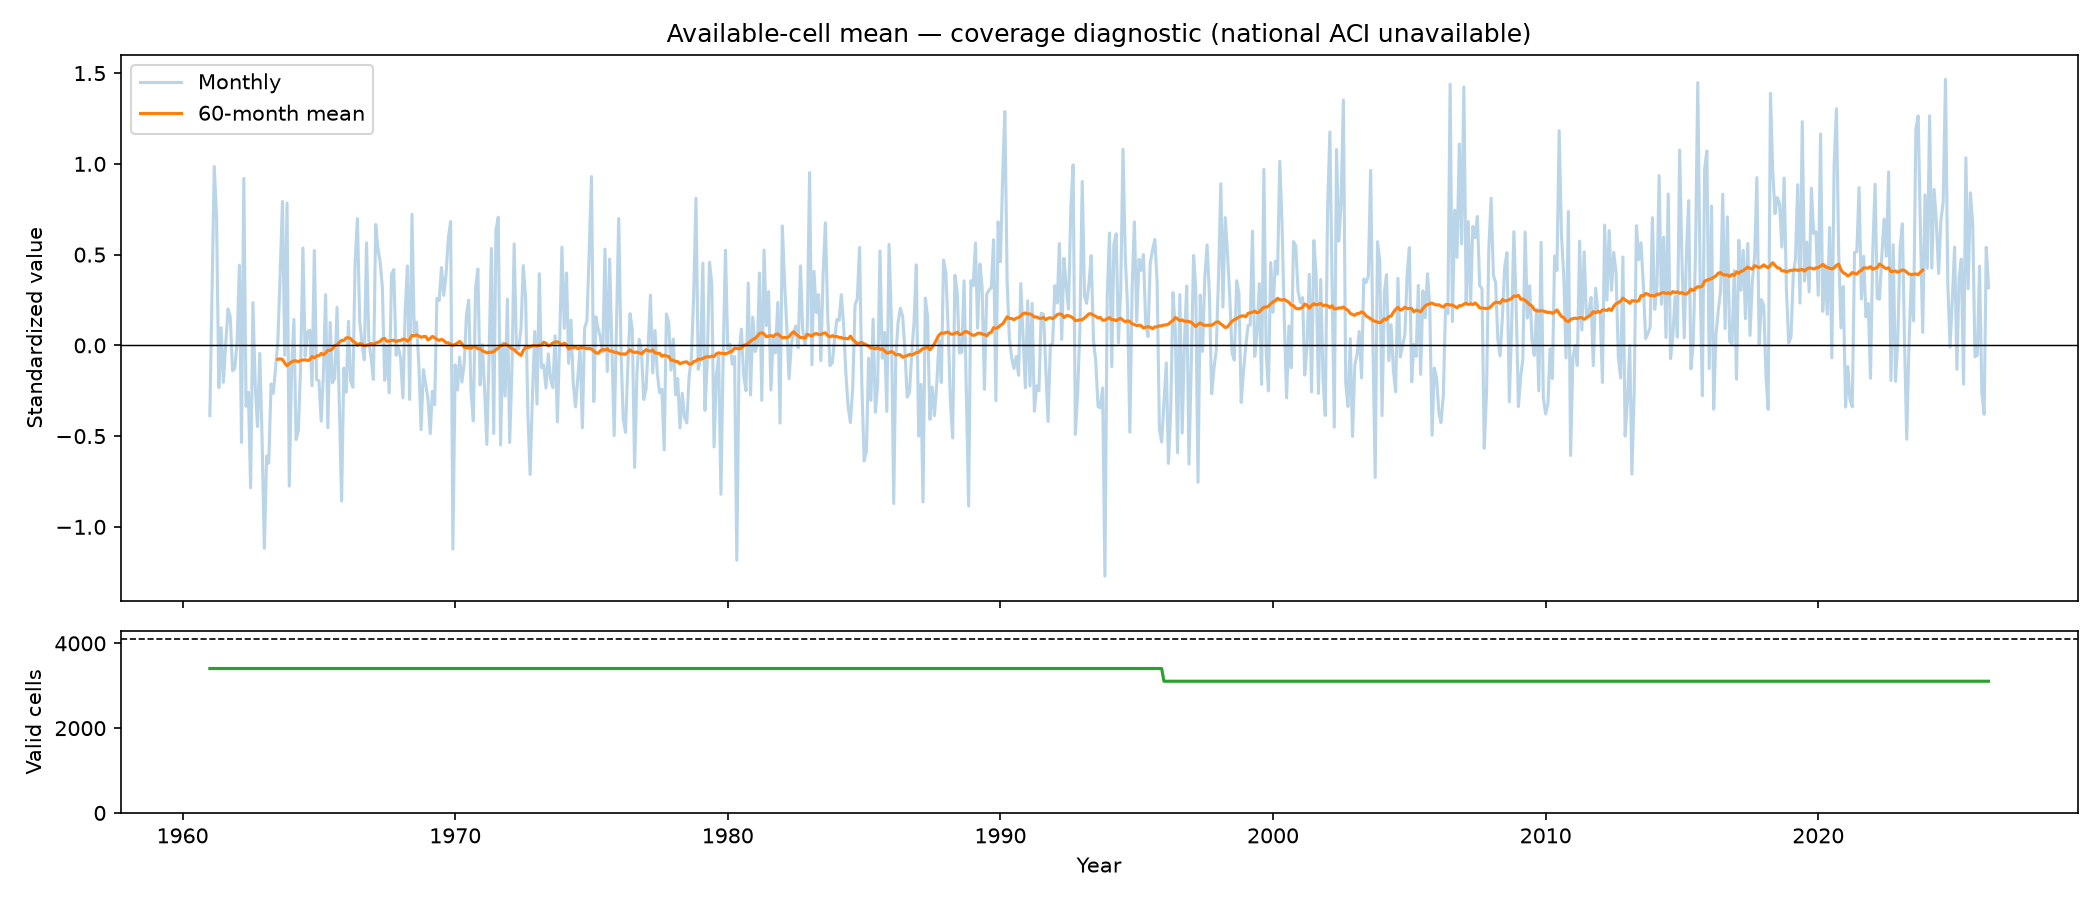

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True, gridspec_kw={"height_ratios":[3,1]})
x = MONTHS.to_timestamp()
if national.ACI_land5.notna().any():
    y = national.ACI_land5
    title = "Poland — national ACI land5"
else:
    y = national.available_cell_mean_DIAGNOSTIC
    title = "Available-cell mean — coverage diagnostic (national ACI unavailable)"
axes[0].plot(x, y, color="tab:blue", alpha=.3, label="Monthly")
axes[0].plot(x, y.rolling(60, center=True, min_periods=60).mean(), color="tab:orange", label="60-month mean")
axes[0].axhline(0, color="black", lw=.7)
axes[0].set(title=title, ylabel="Standardized value")
axes[0].legend()
axes[1].plot(x, cell_counts, color="tab:green")
axes[1].axhline(N, color="black", linestyle="--", linewidth=.8)
axes[1].set(ylabel="Valid cells", ylim=(0, N*1.05), xlabel="Year")
fig.tight_layout()
trend_path = OUTPUT_DIR / "poland_aci_trend_and_coverage.png"
fig.savefig(trend_path, dpi=150)
plt.close(fig)
display(Image(filename=str(trend_path)))


## 8. Map every Polish rectangle

The default view is the latest complete calendar year, **2025**, with annual ACI values. All 4,092 rectangles remain visible; grey means no calculable value. Values use each cell's own reference distribution. The outline uses the existing local boundary file.

The static map prints one decimal place where values exist. The interactive map has metric, year/decade, and annual/season selectors; a checkbox shows/hides cell numbers, and hover gives the value, coordinates, voivodeship, and period count. Pan or zoom to inspect smaller rectangles. Its colour anchors match the previous Pomeranian and Dolnośląskie examples; each metric has a fixed range across periods. Colours outside the reference anchors retain the extreme colour, as in those notebooks. The map includes its plotting library and data, so it works without an internet connection.


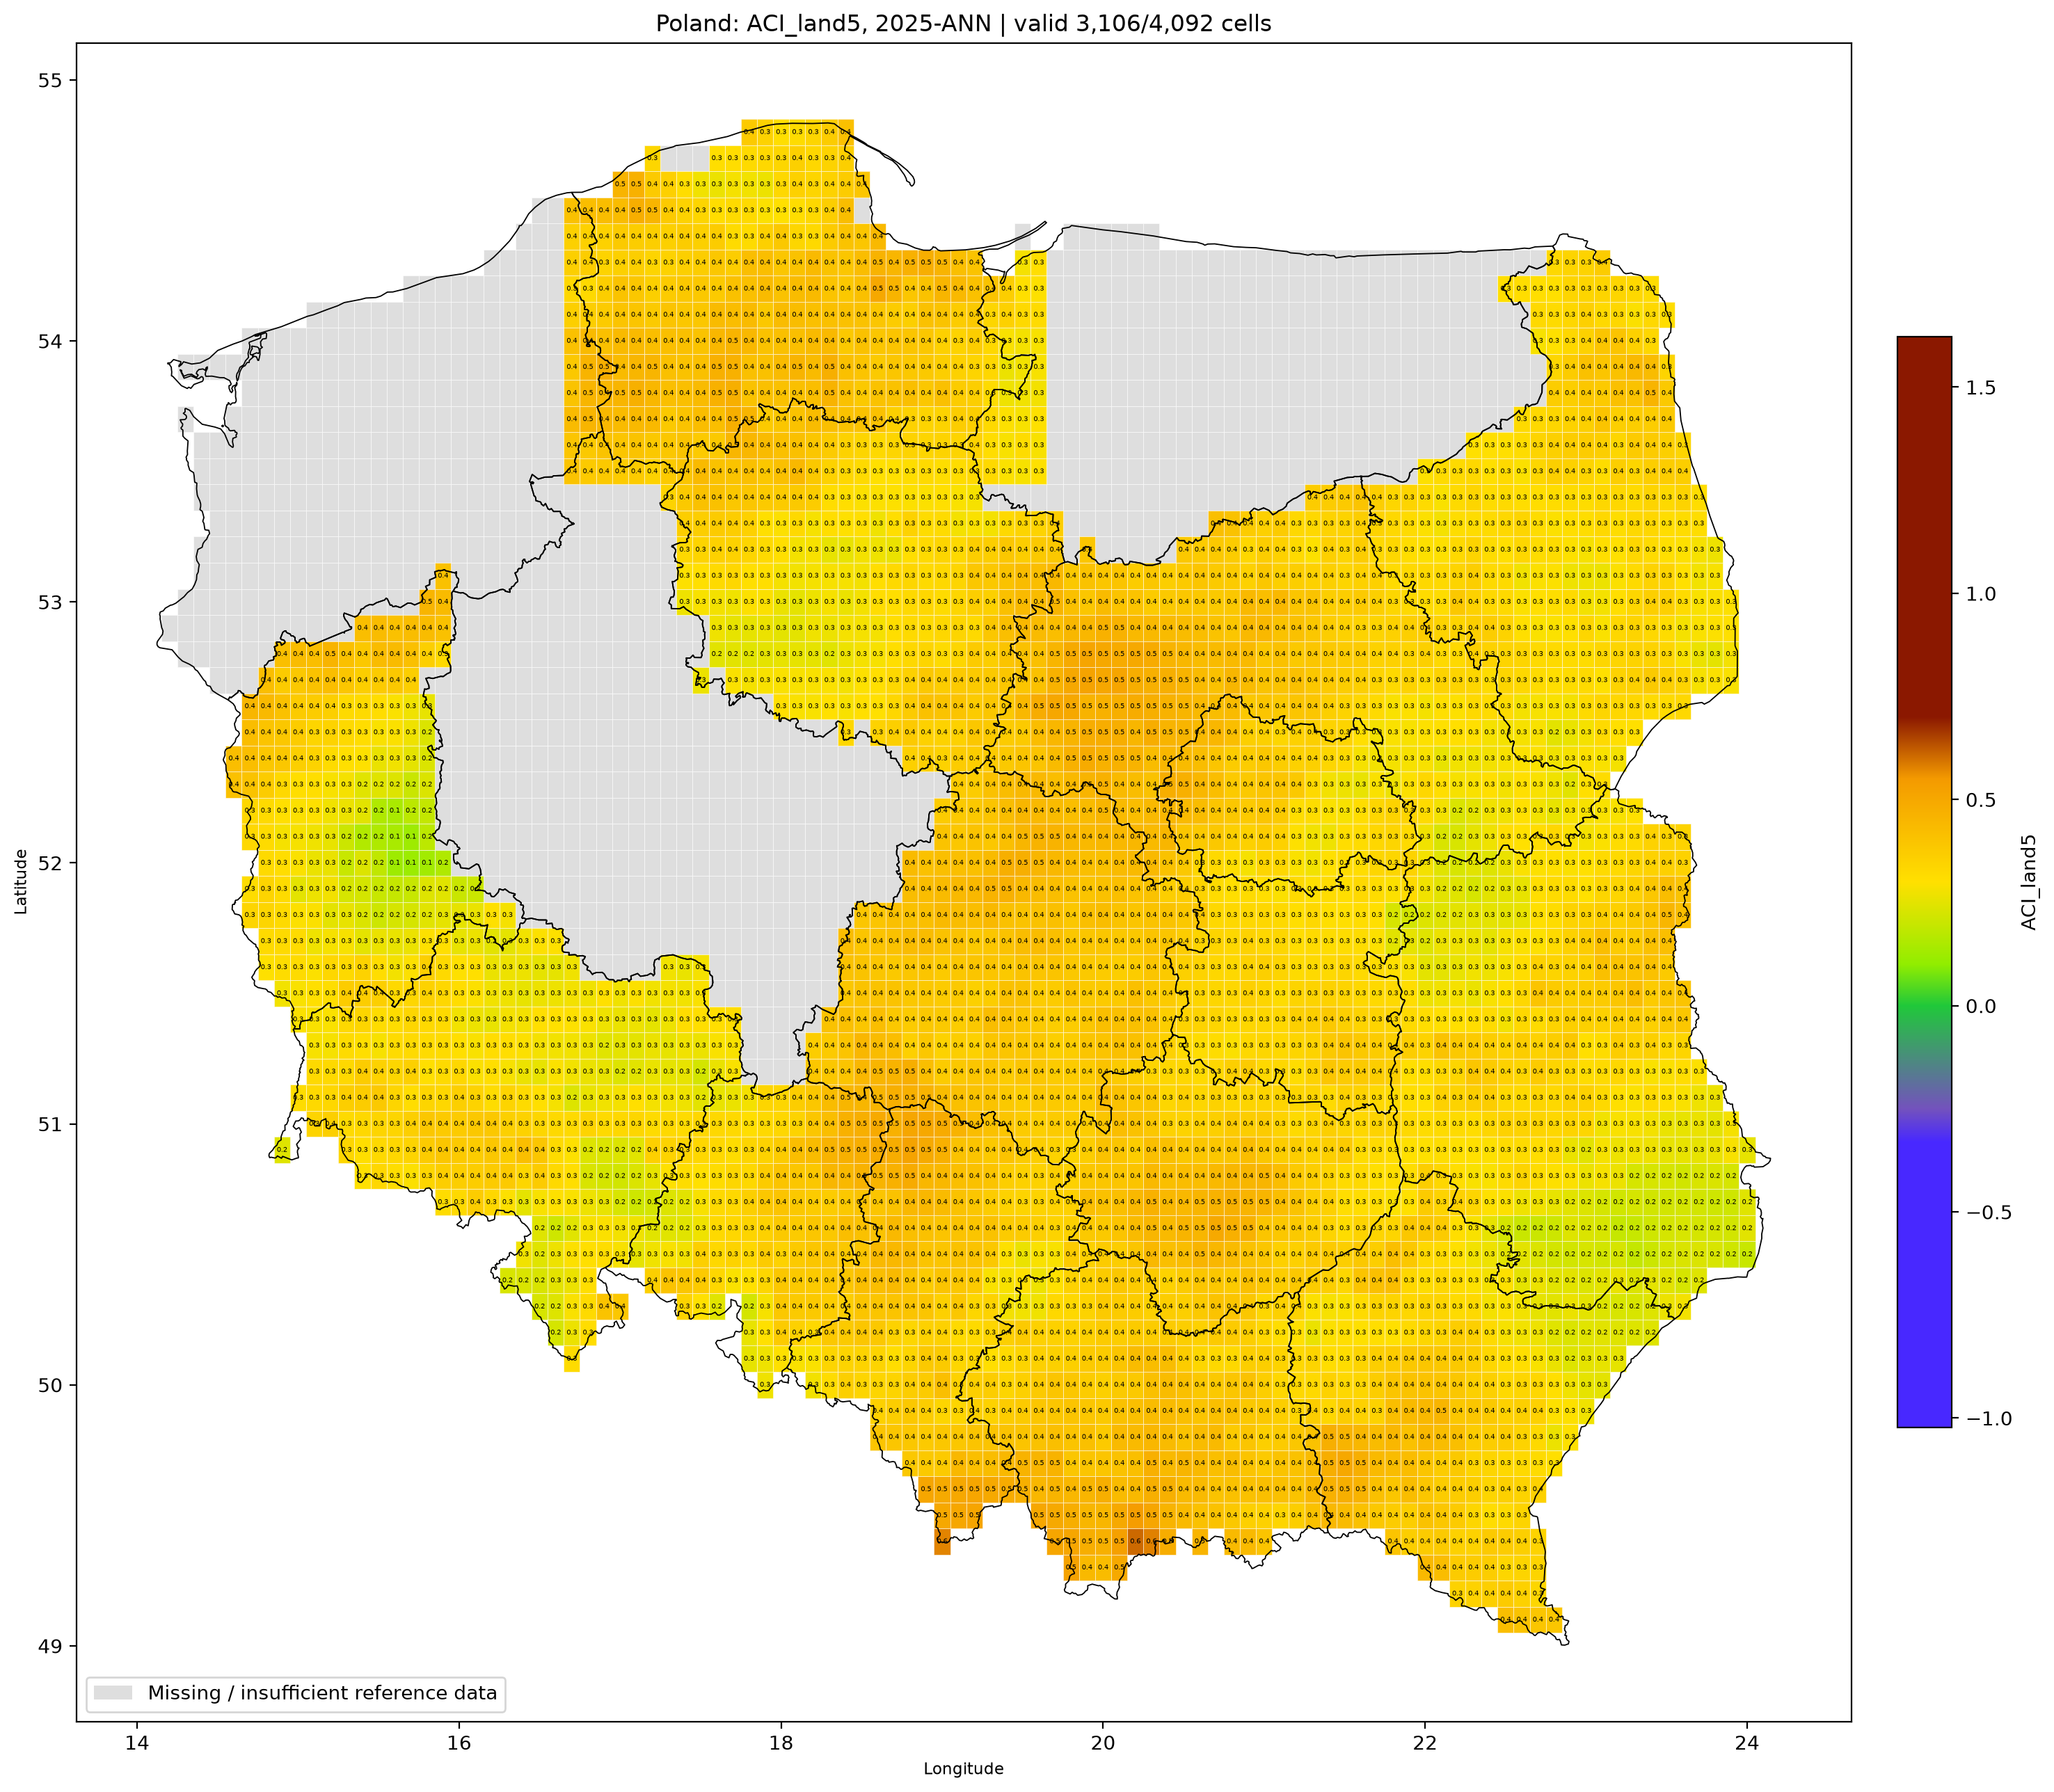

In [10]:
import geopandas as gpd
from shapely.geometry import box
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Patch

MAP_YEAR, MAP_AGGREGATION, MAP_VARIABLE = 2025, "ANN", "ACI_land5"
period_labels = np.concatenate([season_labels, annual_labels])
period_values = np.concatenate([season_values, annual_values], axis=0)
ANCHORS = [(-.33,"#4828ff"),(-.25,"#7352bd"),(0.,"#20c83a"),
           (.10,"#91ed00"),(.30,"#ffe000"),(.55,"#f49a00"),(.70,"#8b1800")]
limits, colours = {}, {}
for j, metric in enumerate(METRICS):
    finite = period_values[:, :, j]
    finite = finite[np.isfinite(finite)]
    low = min(-.33, float(finite.min())) if len(finite) else -.33
    high = max(.70, float(finite.max())) if len(finite) else .70
    anchors = ANCHORS.copy()
    if low < anchors[0][0]: anchors.insert(0, (low, anchors[0][1]))
    if high > anchors[-1][0]: anchors.append((high, anchors[-1][1]))
    limits[metric] = [low, high]
    colours[metric] = [[(v-low)/(high-low), c] for v,c in anchors]

boundary = gpd.read_file(PROJECT_ROOT / "data/poland/boundary/poland_nuts2_2024.geojson").to_crs("EPSG:4326")
tiles = gpd.GeoDataFrame(grid.copy(), geometry=[box(lon-.05,lat-.05,lon+.05,lat+.05)
                          for lat,lon in zip(grid.latitude,grid.longitude)], crs="EPSG:4326")

def plot_poland_map(year=MAP_YEAR, aggregation=MAP_AGGREGATION, metric=MAP_VARIABLE, numbers=True):
    label = f"{year}-{aggregation}"
    index = np.flatnonzero(period_labels == label)
    if len(index) != 1: raise ValueError(f"Unknown period: {label}")
    values = period_values[index[0], :, METRICS.index(metric)]
    plotting = tiles.copy()
    plotting[metric] = values
    cmap = LinearSegmentedColormap.from_list("ACI_reference", colours[metric], N=65536)
    norm = Normalize(*limits[metric])
    fig, ax = plt.subplots(figsize=(17, 13))
    plotting.plot(ax=ax, facecolor="#dedede", edgecolor="white", linewidth=.2)
    plotting.loc[np.isfinite(values)].plot(ax=ax, column=metric, cmap=cmap, norm=norm,
                                         edgecolor="white", linewidth=.2)
    boundary.boundary.plot(ax=ax, color="black", linewidth=.65)
    if numbers:
        for lat, lon, value in zip(grid.latitude, grid.longitude, values):
            if np.isfinite(value): ax.text(lon,lat,f"{value:.1f}",ha="center",va="center",fontsize=3.7)
    fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=ax, shrink=.65, pad=.02, label=metric)
    ax.legend(handles=[Patch(facecolor="#dedede",label="Missing / insufficient reference data")], loc="lower left")
    ax.set(title=f"Poland: {metric}, {label} | valid {np.isfinite(values).sum():,}/{N:,} cells",
           xlabel="Longitude", ylabel="Latitude")
    fig.tight_layout()
    target = OUTPUT_DIR / f"poland_{metric}_{label}_map.png"
    fig.savefig(target, dpi=200, bbox_inches="tight")
    plt.close(fig)
    return target
static_map_path = plot_poland_map()
display(Image(filename=str(static_map_path)))


In [11]:
from plotly.offline import get_plotlyjs

# Compact payload: point arrays, not repeated rectangular matrices. Gzip is decoded locally by the browser.
payload = {"Year":{}, "Decade":{}}
for label, values in zip(period_labels, period_values):
    year, season = label.split("-")
    payload["Year"].setdefault(year, {})[season] = {
        "values": np.where(np.isfinite(values), np.round(values,4), None).tolist(),
        "counts": np.isfinite(values).astype(np.uint8).tolist()}
years = np.asarray([int(s[:4]) for s in period_labels])
seasons = np.asarray([s[5:] for s in period_labels])
for first in range(1961, END.year+1, 10):
    label = f"{first}–{min(first+9, END.year)}"
    for season in ["ANN","DJF","MAM","JJA","SON"]:
        selection = (years >= first) & (years <= first+9) & (seasons == season)
        if not selection.any(): continue
        group = period_values[selection]
        values = safe_mean(group)
        payload["Decade"].setdefault(label, {})[season] = {
            "values": np.where(np.isfinite(values), np.round(values,4), None).tolist(),
            "counts": np.isfinite(group).sum(axis=0).tolist()}
packed = base64.b64encode(gzip.compress(json.dumps(payload, separators=(",",":"), allow_nan=False).encode(), compresslevel=6)).decode()
# Local administrative rings, including the two Mazowieckie NUTS2 parts.
boundary_x, boundary_y = [], []
for geom in boundary.geometry:
    for polygon in (geom.geoms if geom.geom_type == "MultiPolygon" else [geom]):
        for ring in [polygon.exterior, *polygon.interiors]:
            boundary_x.extend([float(p[0]) for p in ring.coords] + [None])
            boundary_y.extend([float(p[1]) for p in ring.coords] + [None])
latitudes = sorted(grid.latitude.unique().tolist())
longitudes = sorted(grid.longitude.unique().tolist())
points = [[float(r.latitude), float(r.longitude), r.voivodeship, r.grid_point_id,
           str(availability.iloc[i].status)] for i,r in enumerate(grid.itertuples())]
constants = {"PACKED":packed,"POINTS":points,"LATS":latitudes,"LONS":longitudes,
             "METRICS":METRICS,"LIMITS":limits,"COLOURS":colours,
             "BOUNDARY":{"x":boundary_x,"y":boundary_y},"DEFAULT_YEAR":str(MAP_YEAR),"N":N}
js_constants = "\n".join("const "+k+"="+json.dumps(v,allow_nan=False)+";" for k,v in constants.items())
js = r"""
const el=id=>document.getElementById(id); let DATA;
const posLat=new Map(LATS.map((v,i)=>[v.toFixed(1),i])),posLon=new Map(LONS.map((v,i)=>[v.toFixed(1),i]));
const empty=()=>LATS.map(()=>LONS.map(()=>null));
function matrix(values){const z=empty();POINTS.forEach((p,i)=>z[posLat.get(p[0].toFixed(1))][posLon.get(p[1].toFixed(1))]=values[i]);return z;}
const missing=matrix(POINTS.map(()=>1));
const info=matrix(POINTS.map(p=>p[2]+'<br>'+p[3]));
async function boot(){
 try{
 const bytes=Uint8Array.from(atob(PACKED),c=>c.charCodeAt(0));
 const stream=new Blob([bytes]).stream().pipeThrough(new DecompressionStream('gzip'));
 DATA=JSON.parse(await new Response(stream).text());
 METRICS.forEach(m=>el('metric').add(new Option(m,m)));el('metric').value='ACI_land5';
 el('loading').textContent='Ready — all data and map code are stored in this file.';
 ['metric','season','numbers'].forEach(id=>el(id).onchange=draw);
 el('mode').onchange=periods;el('period').onchange=draw;periods();
 }catch(e){el('loading').textContent='Could not initialize this offline map: '+e.message;}
}
function periods(){
 el('period').innerHTML='';Object.keys(DATA[el('mode').value]).forEach(y=>el('period').add(new Option(y,y)));
 if(el('mode').value==='Year')el('period').value=DEFAULT_YEAR;draw();
}
function draw(){
 const mode=el('mode').value,p=el('period').value,s=el('season').value,m=el('metric').value,j=METRICS.indexOf(m);
 const d=DATA[mode]?.[p]?.[s];
 const vals=POINTS.map((_,i)=>d?.values[i][j]??null);
 const counts=POINTS.map((_,i)=>d?.counts[i][j]??0);
 const custom=matrix(POINTS.map((pt,i)=>[counts[i],pt[2],pt[3],vals[i]===null?'Missing period or insufficient local reference data':'Calculated']));
 const valid=vals.filter(v=>v!==null).length;
 const unit=s==='ANN'?'years':'seasons';
 const traces=[{type:'heatmap',x:LONS,y:LATS,z:missing,zmin:0,zmax:1,colorscale:[[0,'#dedede'],[1,'#dedede']],
  xgap:1,ygap:1,showscale:false,customdata:custom,hoverongaps:false,
  hovertemplate:'%{customdata[1]}<br>%{customdata[2]}<br>Latitude %{y}, longitude %{x}<br>No value for this period<br>%{customdata[4]}<extra></extra>'},
 {type:'heatmap',x:LONS,y:LATS,z:matrix(vals),zmin:LIMITS[m][0],zmax:LIMITS[m][1],colorscale:COLOURS[m],
  xgap:1,ygap:1,customdata:custom,hoverongaps:false,texttemplate:el('numbers').checked?'%{z:.1f}':'',textfont:{size:6,color:'black'},
  colorbar:{title:{text:m},tickvals:[LIMITS[m][0],-.33,-.25,0,.10,.30,.55,.70,LIMITS[m][1]]},
  hovertemplate:'%{customdata[1]}<br>%{customdata[2]}<br>Latitude %{y}, longitude %{x}<br>Value %{z:.4f}<br>Complete '+unit+': %{customdata[0]}<extra></extra>'},
 {type:'scatter',mode:'lines',x:BOUNDARY.x,y:BOUNDARY.y,line:{color:'black',width:1},hoverinfo:'skip',showlegend:false}];
 Plotly.react('map',traces,{title:{text:m+' | '+p+' | '+s+' | '+valid.toLocaleString()+'/'+N.toLocaleString()+' cells'},
  height:950,uirevision:'keep-zoom',xaxis:{title:{text:'Longitude'},range:[Math.min(...LONS)-.15,Math.max(...LONS)+.15]},
  yaxis:{title:{text:'Latitude'},range:[Math.min(...LATS)-.15,Math.max(...LATS)+.15],scaleanchor:'x',scaleratio:1/Math.cos(52*Math.PI/180)},
  margin:{t:65,l:55,b:50,r:130},paper_bgcolor:'white'}, {responsive:true,scrollZoom:true,displaylogo:false});
 el('coverage').textContent=(N-valid).toLocaleString()+' grey rectangles have no calculable value. '+
 (mode==='Decade'?'Decades use complete constituent periods only; hover to see their count.':'Annual values require 12 months; seasonal values require 3.');
}
boot();
"""
controls = """<h1>Poland — ACI land5 by rectangle</h1>
<p>Reference: 1961–1991 inclusive. Five land components; water level excluded.
Cell indices use local baselines. A complete national index is unavailable when national coverage is incomplete.</p>
<label>Component <select id="metric"></select></label>
<label>View <select id="mode"><option>Year</option><option>Decade</option></select></label>
<label>Period <select id="period"></select></label>
<label>Average <select id="season"><option value="ANN">Full year</option><option>DJF</option><option>MAM</option><option>JJA</option><option>SON</option></select></label>
<label><input type="checkbox" id="numbers" checked>Values in rectangles</label>
<p id="loading">Loading local map data…</p><p id="coverage"></p>
<p>Grey = missing. Hover to inspect values. Drag to pan, scroll to zoom, double-click to reset.
Colour anchors follow the previous ACI maps; scales are fixed per component across periods.</p><div id="map"></div>"""
html = '<!doctype html><html lang="en"><head><meta charset="utf-8"><title>Poland ACI map</title>' +        '<style>body{font:15px system-ui;margin:24px;color:#17202a}h1{font-size:26px}select{padding:7px;margin:5px}label{display:inline-block}#loading,#coverage{color:#555}</style>' +        '<script>'+get_plotlyjs()+'</script></head><body>'+controls+'<script>'+js_constants+'\n'+js+'</script></body></html>'
map_path = OUTPUT_DIR / "poland_aci_interactive_map.html"
map_path.write_text(html, encoding="utf-8")
# A relative iframe keeps the saved notebook compact; the linked HTML is self-contained.
display(HTML('<p><a href="output/poland/national/poland_aci_interactive_map.html" target="_blank">Open the standalone interactive Poland map</a></p>'))
display(IFrame(src="output/poland/national/poland_aci_interactive_map.html", width="100%", height=1150))
print("Offline interactive map:", map_path)
print("Static map:", static_map_path)
del payload, packed, html, constants, js_constants


Offline interactive map: /home/magda/Projects/Climate_index/output/poland/national/poland_aci_interactive_map.html
Static map: /home/magda/Projects/Climate_index/output/poland/national/poland_ACI_land5_2025-ANN_map.png


## 9. Assessment and output guide

The following generated report records the actual coverage found on this run. It lists any missing areas rather than claiming that a partial footprint represents all Poland. To extend the result later, place additional **already available local** daily/hourly files in the regional folders and rerun. No download step is provided.

Main outputs:

- `poland_assessment.json`, `poland_grid_availability.csv`, and `poland_voivodeship_coverage.csv`: feasibility and gaps.
- `poland_local_source_audit.csv`: local files used and their contribution; `poland_source_issues.csv`: skipped archive issues.
- `poland_national_monthly.csv`: national components/ACI when supported, plus explicitly labelled available-cell diagnostics and counts.
- `poland_grid_components_monthly.nc`, `poland_grid_components_seasonal.nc`, `poland_grid_components_annual.nc`: independent cell results for all rectangles.
- `poland_aci_interactive_map.html`: complete offline interactive map; `poland_ACI_land5_2025-ANN_map.png`: default static map.
- `poland_method_validation.csv`: numerical agreement with the previous calculations.


In [12]:
incomplete = region_summary.loc[region_summary.fully_complete_cells < region_summary.rectangles]
lines = ["# Poland ACI — local-data assessment", "", f"Grid: {N:,} unique rectangles across 16 voivodeships.",
         f"Period: {START.date()}–{END.date()}; reference: {BASE_RANGE[0]}–{BASE_RANGE[1]} inclusive.",
         "Water level excluded everywhere. No downloads attempted.", "",
         f"Complete daily period: {summary['cells_with_full_daily_period']:,}/{N:,} cells.",
         f"Complete reference period: {summary['complete_reference_cells']:,}/{N:,} cells.",
         f"Valid national ACI months: {summary['valid_national_aci_months']}/{len(MONTHS)}.",
         f"Latest month ({MONTHS[-1]}) valid cell ACI: {int(cell_counts[-1]):,}/{N:,}.", ""]
if not NATIONAL_REFERENCE_READY:
    lines += ["A complete all-Poland ACI cannot be calculated from these local files.",
              "The national result is missing rather than calculated from a changing subset.",
              "All grid rectangles are mapped; grey rectangles have no supported value.", ""]
lines += ["## Regions with incomplete daily coverage", "", incomplete.to_string(), "",
          "Some additional points were recovered from the earlier Pomeranian rectangle archive; see the source audit.",
          "Local hourly years were converted only when complete and when the corresponding daily year was absent.",
          "Partial archives were ignored. Input files and previous notebooks were not modified.", "",
          f"Numerical formula checks: {len(validation)} comparisons passed, plus a missing-day mask check.",
          "", "Open poland_aci_interactive_map.html in a browser for the offline map."]
report = "\n".join(lines)
(OUTPUT_DIR / "README.md").write_text(report, encoding="utf-8")
print(report)


# Poland ACI — local-data assessment

Grid: 4,092 unique rectangles across 16 voivodeships.
Period: 1961-01-01–2026-04-30; reference: 1961–1991 inclusive.
Water level excluded everywhere. No downloads attempted.

Complete daily period: 3,106/4,092 cells.
Complete reference period: 3,406/4,092 cells.
Valid national ACI months: 0/784.
Latest month (2026-04) valid cell ACI: 3,106/4,092.

A complete all-Poland ACI cannot be calculated from these local files.
The national result is missing rather than calculated from a changing subset.
All grid rectangles are mapped; grey rectangles have no supported value.

## Regions with incomplete daily coverage

                     rectangles  complete_reference  complete_weather_days_min  complete_weather_days_max  valid_aci_months_min  valid_aci_months_max  fully_complete_cells
region                                                                                                                                                                     
po